[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HesusG/dammg-supervisado/blob/main/notebooks/demos/D3_mse_mle.ipynb)

# D3 · MSE = máxima verosimilitud con ruido gaussiano

*DAMMG · Módulo VI · Aprendizaje supervisado · FC-UNAM*

**Recuerden (Mód V).** Verosimilitud de datos independientes = producto; $\log$ es creciente, así que maximizar $L$ o $\log L$ da lo mismo.

**Supuestos.** $y^{(i)}=f(x^{(i)})+\varepsilon^{(i)}$ con $\varepsilon^{(i)}\sim\mathcal N(0,\sigma^2)$ **i.i.d.** y **varianza constante**. Contraejemplo: ruido de Laplace $\Rightarrow$ el MLE minimiza el MAE.

**La idea.** Con ruido gaussiano, $-\ell(\vec w,b)=\frac{m}{\sigma^2}J(\vec w,b)+\text{const}$. Graficamos $\ell(w)$ (perfil: para cada $w$ usamos el mejor $b$) y vemos que su máximo cae en el $\hat w$ de mínimos cuadrados. Con un dato atípico, la verosimilitud de Laplace se queda cerca de la mayoría y la gaussiana se deja arrastrar.

La derivación completa está en `anexos/derivaciones.pdf`.

In [1]:
%matplotlib inline
import sys, pathlib
# dammg_utils vive en notebooks/ (en Colab se descarga junto al notebook)
for p in (pathlib.Path("..").resolve(), pathlib.Path(".").resolve()):
    if (p / "dammg_utils.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import matplotlib.pyplot as plt
from dammg_utils import estilo_dammg, COLORES
estilo_dammg()
C = COLORES
np.set_printoptions(precision=4, suppress=True)

## Parámetros
Si los controles no aparecen (por ejemplo, en el PDF), cambien el valor aquí y ejecuten de nuevo.

In [2]:
# Parámetro del ¿qué pasa si...?
ATIPICO = 0.0   # tamaño del dato atípico que se suma a la última observación (0 = sin atípico)

## La identidad, con números

argmax ℓ gaussiana = 2.175   ŵ OLS = 2.176
argmax ℓ Laplace   = 2.125   ŵ MAE = 2.124
σ̂² (MLE) = 2·J(ŵ) = 1.219


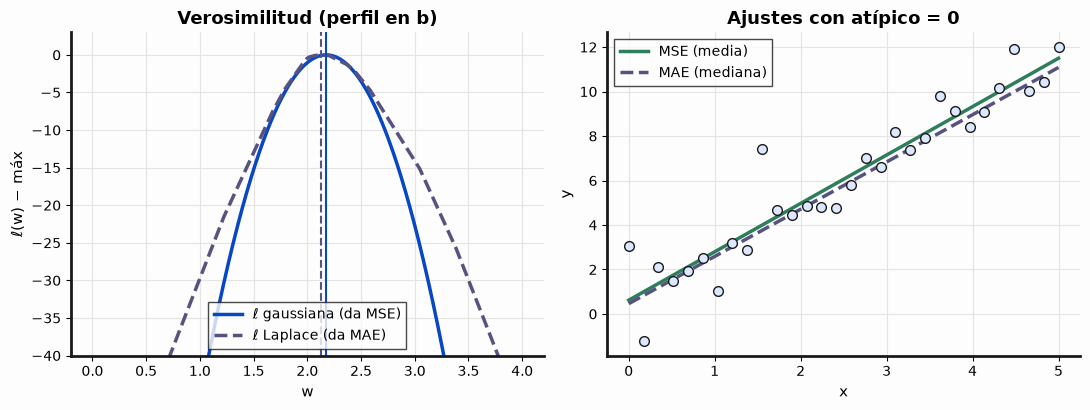

In [3]:
from sklearn.linear_model import LinearRegression, QuantileRegressor

rng = np.random.default_rng(3)
m = 30
x = np.linspace(0, 5, m)
y0 = 2.0 * x + 1.0 + rng.normal(scale=1.0, size=m)

def demo(atipico=ATIPICO):
    y = y0.copy(); y[-1] += atipico
    ws = np.linspace(0, 4, 801)
    # perfil gaussiano: b óptimo = media(y − w x); Laplace: b óptimo = mediana(y − w x)
    sigma2, beta = 1.0, 1.0
    ell_g = np.array([-(m / 2) * np.log(2 * np.pi * sigma2) - np.sum((y - w * x - np.mean(y - w * x))**2) / (2 * sigma2) for w in ws])
    ell_l = np.array([-m * np.log(2 * beta) - np.sum(np.abs(y - w * x - np.median(y - w * x))) / beta for w in ws])
    ols = LinearRegression().fit(x[:, None], y)
    lad = QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs").fit(x[:, None], y)
    w_g, w_l = ws[ell_g.argmax()], ws[ell_l.argmax()]
    print(f"argmax ℓ gaussiana = {w_g:.3f}   ŵ OLS = {ols.coef_[0]:.3f}")
    print(f"argmax ℓ Laplace   = {w_l:.3f}   ŵ MAE = {lad.coef_[0]:.3f}")
    assert abs(w_g - ols.coef_[0]) < 0.01
    J = np.mean((ols.predict(x[:, None]) - y)**2) / 2
    print(f"σ̂² (MLE) = 2·J(ŵ) = {2 * J:.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(ws, ell_g - ell_g.max(), color=C["w"], label="ℓ gaussiana (da MSE)")
    ax[0].plot(ws, ell_l - ell_l.max(), color=C["b"], linestyle="--", label="ℓ Laplace (da MAE)")
    ax[0].axvline(ols.coef_[0], color=C["w"], linewidth=1.5)
    ax[0].axvline(lad.coef_[0], color=C["b"], linewidth=1.5, linestyle="--")
    ax[0].set(ylim=(-40, 3), xlabel="w", ylabel="ℓ(w) − máx", title="Verosimilitud (perfil en b)")
    ax[0].legend(loc="lower center")
    ax[1].scatter(x, y, color=C["datos"], edgecolor=C["tinta"], zorder=3)
    xx = np.array([0, 5.0])
    ax[1].plot(xx, ols.predict(xx[:, None]), color=C["yhat"], label="MSE (media)")
    ax[1].plot(xx, lad.predict(xx[:, None]), color=C["b"], linestyle="--", label="MAE (mediana)")
    ax[1].set(xlabel="x", ylabel="y", title=f"Ajustes con atípico = {atipico:g}")
    ax[1].legend(loc="upper left")
    fig.tight_layout(); plt.show()

demo()

**¿Qué pasa si…?** Predigan: con un atípico de $+40$, ¿cuál recta se mueve más, la de MSE o la de MAE? ¿Por qué?

Respuesta esperada: la de MSE. Bajo ruido gaussiano un error de 40 es casi imposible ($e^{-800}$), así que el MLE gaussiano mueve la recta para explicarlo. Bajo Laplace el castigo crece solo linealmente.

In [4]:
# ¿Qué pasa si...? Muevan el control. Sin ipywidgets: cambien el parámetro arriba y vuelvan a ejecutar.
try:
    import ipywidgets as W
    W.interact(demo, atipico=W.FloatSlider(value=ATIPICO, min=-40, max=40, step=1, description='atípico', continuous_update=False))
except ImportError:
    print('ipywidgets no está instalado: usen la celda de parámetros.')